In [34]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [35]:
df = pd.read_csv("Student_Performance.csv")

In [36]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [37]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 490.6 KB


In [39]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='str')

In [40]:
df.shape

(10000, 6)

In [41]:
df.isna().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1572
Sleep Hours                            0
Sample Question Papers Practiced    2856
Performance Index                      0
dtype: int64

In [42]:
df.duplicated().sum()

np.int64(132)

In [43]:
df.drop_duplicates(inplace=True)

In [44]:
df.duplicated().sum()

np.int64(0)

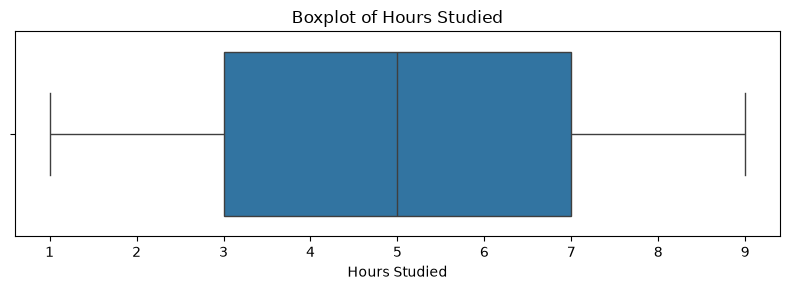

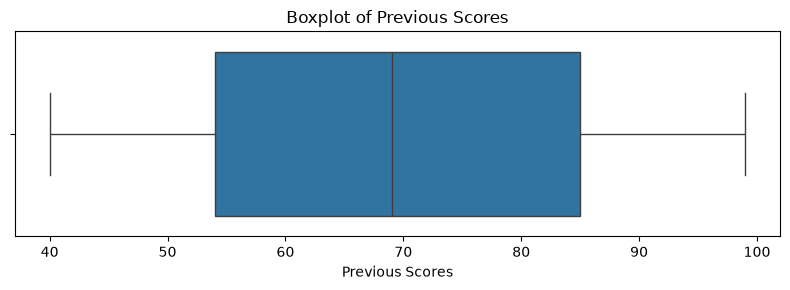

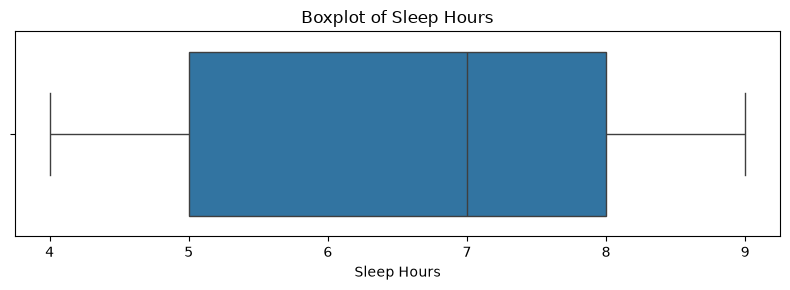

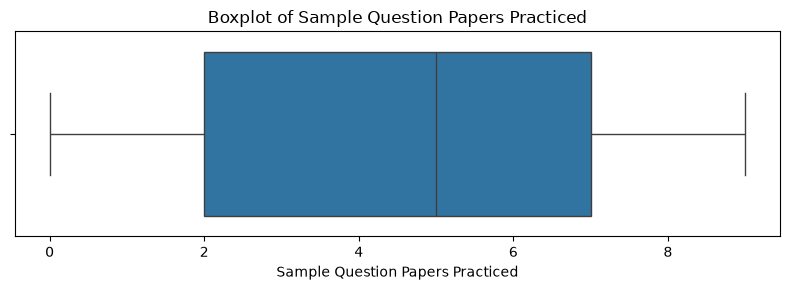

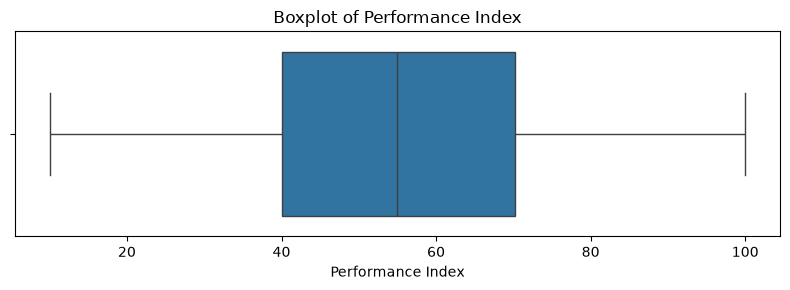

In [45]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

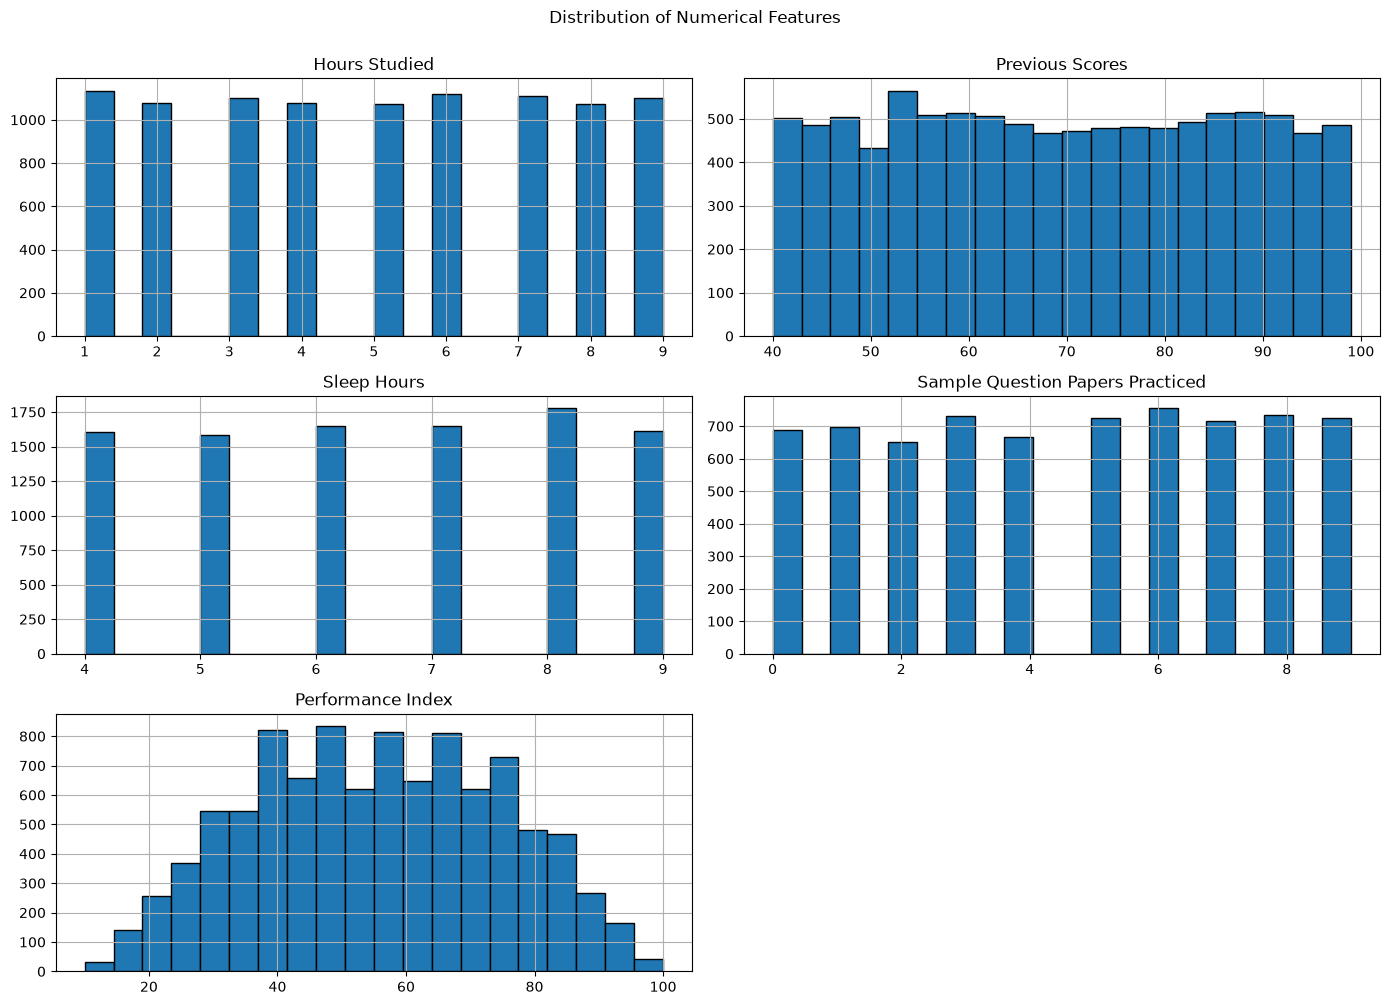

In [46]:
numeric_cols = df.select_dtypes(include="number").columns

df[numeric_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", y=1)
plt.tight_layout()
plt.show()

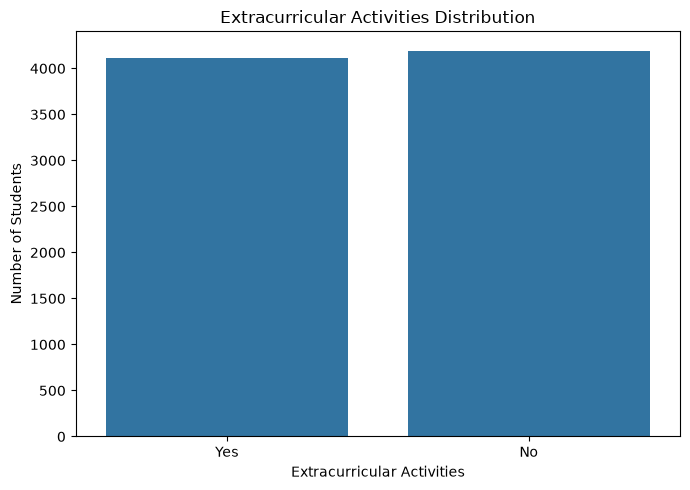

In [47]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Extracurricular Activities",
    order=["Yes", "No"]
)

plt.title("Extracurricular Activities Distribution")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

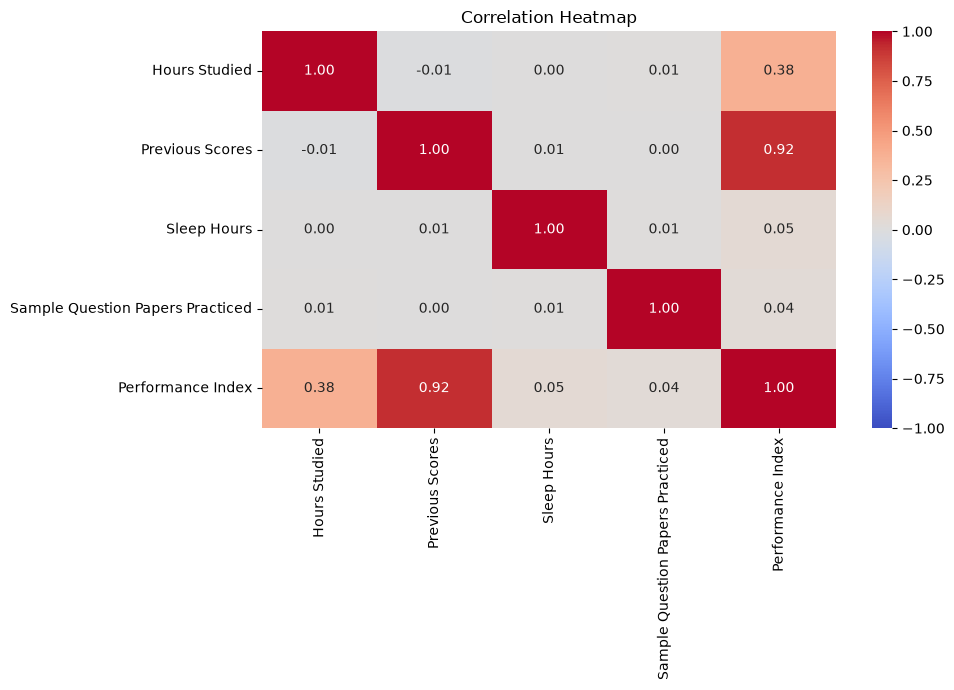

In [48]:
plt.figure(figsize=(10, 7))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

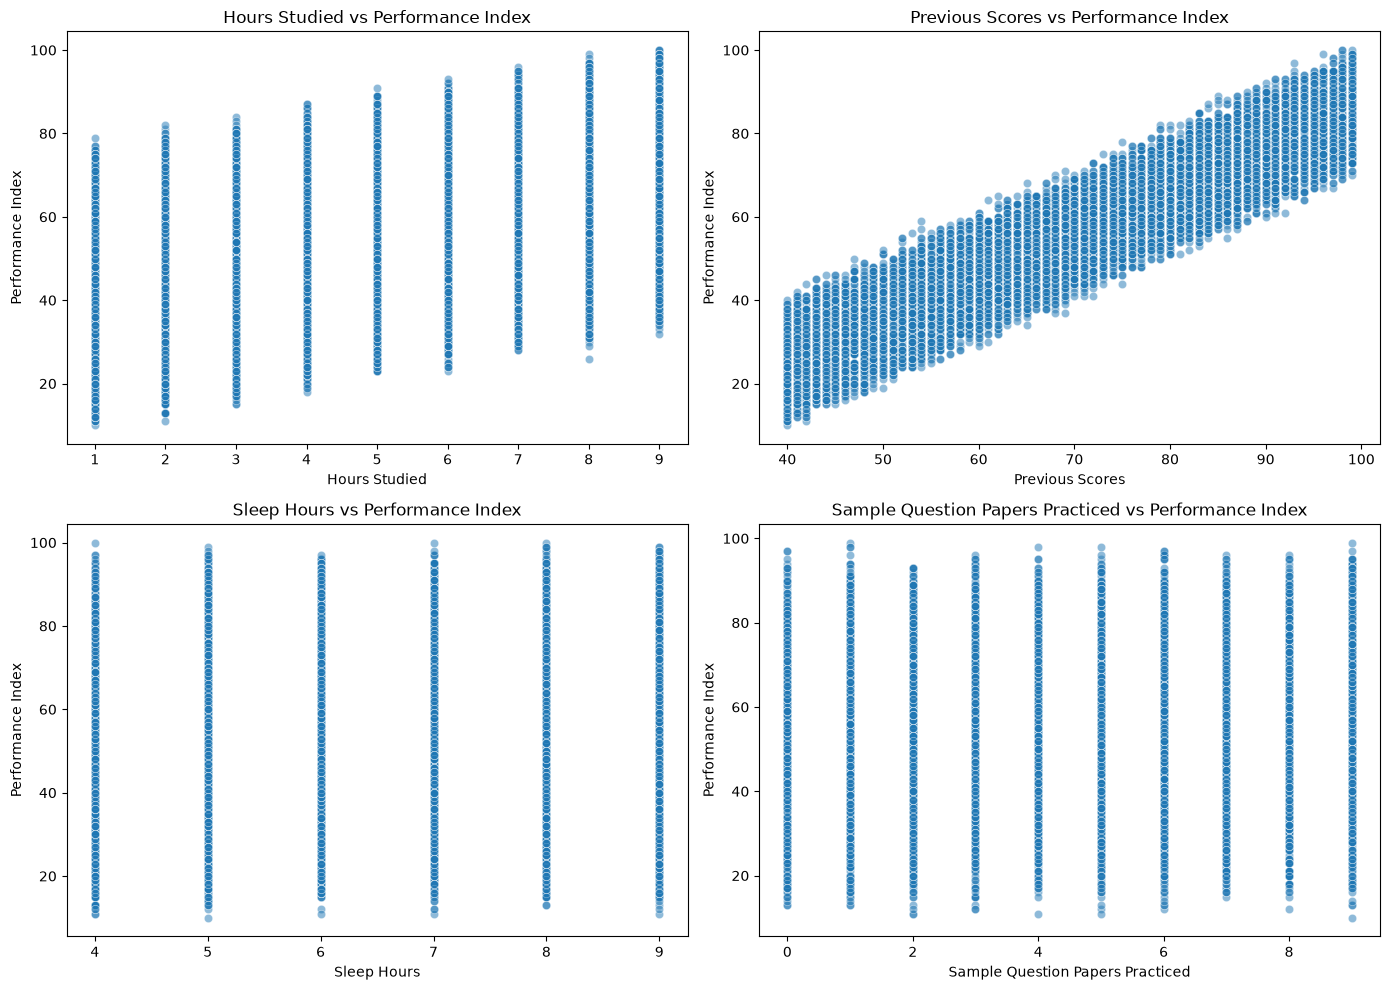

In [49]:
features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=col,
        y="Performance Index",
        alpha=0.5,
        ax=ax
    )

    ax.set_title(f"{col} vs Performance Index")

plt.tight_layout()
plt.show()

In [50]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [51]:
numeric_features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

categorical_features = [
    "Extracurricular Activities"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="if_binary",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [52]:
X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (7894, 5)
X_test: (1974, 5)


In [54]:
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [55]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.6541240894067495
RMSE: 2.0769502731617946
R2 Score: 0.9885937587961464


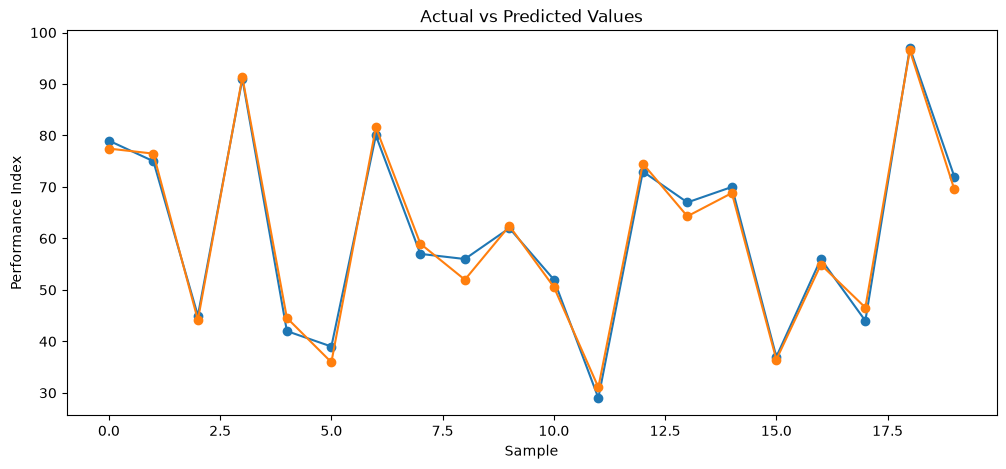

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(y_pred[:20], marker='o', label='Predicted')

plt.xlabel('Sample')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted Values')

plt.show()

In [57]:
from sklearn.neighbors import KNeighborsRegressor

In [58]:
from sklearn.metrics import accuracy_score, r2_score, f1_score,mean_absolute_error,mean_squared_error,root_mean_squared_error

In [59]:
models ={"KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1)}

In [60]:
X_train['Extracurricular Activities'] = (
    X_train['Extracurricular Activities'].map({
        'Yes': 1,
        'No': 0
    })
)

X_test['Extracurricular Activities'] = (
    X_test['Extracurricular Activities'].map({
        'Yes': 1,
        'No': 0
    })
)

In [61]:
print(X_train.select_dtypes(include=['object', 'category']).columns)

Index([], dtype='str')


In [62]:
from sklearn.impute import SimpleImputer

# Impute missing values
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [63]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


In [64]:
errors=[]
for model_name , model in models.items():
    model.fit(X_train, y_train)
    MAE_Train = mean_absolute_error(y_train,model.predict(X_train))
    MAE_Test  =  mean_absolute_error(y_test,model.predict(X_test))

    MSE_Train = mean_squared_error(y_train,model.predict(X_train))
    MSE_Test  =  mean_squared_error(y_test,model.predict(X_test))

    RMSE_Train = root_mean_squared_error(y_train,model.predict(X_train))
    RMSE_Test  =  root_mean_squared_error(y_test,model.predict(X_test))

    R_Train = r2_score(y_train,model.predict(X_train))
    R_Test  =  r2_score(y_test,model.predict(X_test))
    
    errors.append([MAE_Train,MSE_Train,RMSE_Train,R_Train,MAE_Test,MSE_Test,RMSE_Test,R_Test])
    #print(Acc_train,Acc_test)

In [65]:
pd.DataFrame(errors,columns=["MAE_Train","MSE_Train","RMSE_Train","R_Train","MAE_Test","MSE_Test","RMSE_Test","R_Test"],index=models.keys())

,MAE_Train,MSE_Train,RMSE_Train,R_Train,MAE_Test,MSE_Test,RMSE_Test,R_Test
KNN,1.649278,4.2985,2.073282,0.98829,2.027356,6.453212,2.540317,0.982937


In [66]:
# =========================
# Apply All Regression Models
# =========================
# This section applies the complete model set from Regression Models.ipynb
# to the prepared X_train, X_test, y_train, y_test variables.

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
    AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
    VotingRegressor, StackingRegressor
)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric="minkowski", p=1),
    "SVM": SVR(kernel="linear", C=100, gamma=1),
    "Decision Tree": DecisionTreeRegressor(criterion="squared_error", max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion="squared_error", max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion="squared_error", max_depth=10, random_state=42), n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

regression_results = []
regression_fitted = {}

def regression_metrics(model, X, y_actual):
    pred = np.asarray(model.predict(X)).ravel()
    actual = np.asarray(y_actual).ravel()
    mse = mean_squared_error(actual, pred)
    return {
        "MAE": mean_absolute_error(actual, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, pred)
    }

for name, model in regression_models.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    model.fit(X_train, np.asarray(y_train).ravel())
    regression_fitted[name] = model

    train_m = regression_metrics(model, X_train, y_train)
    test_m = regression_metrics(model, X_test, y_test)
    regression_results.append({
        "Model": name,
        "MAE Train": train_m["MAE"], "MAE Test": test_m["MAE"],
        "MSE Train": train_m["MSE"], "MSE Test": test_m["MSE"],
        "RMSE Train": train_m["RMSE"], "RMSE Test": test_m["RMSE"],
        "R2 Train": train_m["R2"], "R2 Test": test_m["R2"]
    })

regression_results_df = pd.DataFrame(regression_results).sort_values(
    by="R2 Test", ascending=False
).reset_index(drop=True)
regression_results_df.round(4)



Linear Regression

Lasso

Ridge

KNN

SVM

Decision Tree

Random Forest

ExtraTrees

Bagging

AdaBoost

GradientBoosting

HistGradientBoosting

XGBoost

CatBoost

LightGBM
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000138 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 90
[LightGBM] [Info] Number of data points in the train set: 7894, number of used features: 5
[LightGBM] [Info] Start training from score 55.300988


,Model,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
0,SVM,1.6452,1.6534,4.2971,4.3113,2.0729,2.0764,0.9883,0.9886
1,Linear Regression,1.6453,1.6541,4.2962,4.3137,2.0727,2.0770,0.9883,0.9886
2,Ridge,1.6453,1.6541,4.2962,4.3137,2.0727,2.0770,0.9883,0.9886
3,LightGBM,1.5367,1.7221,3.7490,4.6295,1.9362,2.1516,0.9898,0.9878
4,HistGradientBoosting,1.5367,1.7226,3.7490,4.6306,1.9362,2.1519,0.9898,0.9878
5,CatBoost,1.6418,1.7273,4.2762,4.6503,2.0679,2.1565,0.9884,0.9877
6,GradientBoosting,1.6387,1.7230,4.2563,4.6731,2.0631,2.1617,0.9884,0.9876
7,XGBoost,1.4614,1.7535,3.4019,4.8061,1.8444,2.1923,0.9907,0.9873
8,Lasso,1.7757,1.7971,5.0105,5.0020,2.2384,2.2365,0.9864,0.9868
9,Random Forest,1.3259,1.8287,2.7639,5.2342,1.6625,2.2878,0.9925,0.9862


In [67]:
# =========================
# Voting Regressor
# =========================
voting_regressor = VotingRegressor(estimators=[
    ("lr", LinearRegression()),
    ("rf", RandomForestRegressor(n_estimators=50, random_state=42)),
    ("dt", DecisionTreeRegressor(random_state=42))
])
voting_regressor.fit(X_train, np.asarray(y_train).ravel())

test_m = regression_metrics(voting_regressor, X_test, y_test)
train_m = regression_metrics(voting_regressor, X_train, y_train)
regression_results_df = pd.concat([regression_results_df, pd.DataFrame([{
    "Model": "Voting Regressor",
    "MAE Train": train_m["MAE"], "MAE Test": test_m["MAE"],
    "MSE Train": train_m["MSE"], "MSE Test": test_m["MSE"],
    "RMSE Train": train_m["RMSE"], "RMSE Test": test_m["RMSE"],
    "R2 Train": train_m["R2"], "R2 Test": test_m["R2"]
}])], ignore_index=True)


In [68]:
# =========================
# Weighted Voting Regressor
# =========================
weighted_voting_regressor = VotingRegressor(
    estimators=[
        ("lr", LinearRegression()),
        ("rf", RandomForestRegressor(n_estimators=50, random_state=42)),
        ("dt", DecisionTreeRegressor(random_state=42))
    ],
    weights=[2, 1, 2]
)
weighted_voting_regressor.fit(X_train, np.asarray(y_train).ravel())

test_m = regression_metrics(weighted_voting_regressor, X_test, y_test)
train_m = regression_metrics(weighted_voting_regressor, X_train, y_train)
regression_results_df = pd.concat([regression_results_df, pd.DataFrame([{
    "Model": "Weighted Voting Regressor",
    "MAE Train": train_m["MAE"], "MAE Test": test_m["MAE"],
    "MSE Train": train_m["MSE"], "MSE Test": test_m["MSE"],
    "RMSE Train": train_m["RMSE"], "RMSE Test": test_m["RMSE"],
    "R2 Train": train_m["R2"], "R2 Test": test_m["R2"]
}])], ignore_index=True)


In [69]:
# =========================
# Stacking Regressor
# =========================
stacking_regressor = StackingRegressor(
    estimators=[
        ("rf", RandomForestRegressor(n_estimators=50, random_state=42)),
        ("gb", GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
        ("cat", CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0, random_state=42)),
        ("lgb", LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
    ],
    final_estimator=XGBRegressor(n_estimators=100, random_state=42, verbosity=0),
    cv=5,
    passthrough=True,
    n_jobs=-1
)
stacking_regressor.fit(X_train, np.asarray(y_train).ravel())

test_m = regression_metrics(stacking_regressor, X_test, y_test)
train_m = regression_metrics(stacking_regressor, X_train, y_train)
regression_results_df = pd.concat([regression_results_df, pd.DataFrame([{
    "Model": "Stacking Regressor",
    "MAE Train": train_m["MAE"], "MAE Test": test_m["MAE"],
    "MSE Train": train_m["MSE"], "MSE Test": test_m["MSE"],
    "RMSE Train": train_m["RMSE"], "RMSE Test": test_m["RMSE"],
    "R2 Train": train_m["R2"], "R2 Test": test_m["R2"]
}])], ignore_index=True)

regression_results_df = regression_results_df.sort_values(
    by="R2 Test", ascending=False
).reset_index(drop=True)
regression_results_df.round(4)


,Model,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
0,SVM,1.6452,1.6534,4.2971,4.3113,2.0729,2.0764,0.9883,0.9886
1,Linear Regression,1.6453,1.6541,4.2962,4.3137,2.0727,2.0770,0.9883,0.9886
2,Ridge,1.6453,1.6541,4.2962,4.3137,2.0727,2.0770,0.9883,0.9886
3,LightGBM,1.5367,1.7221,3.7490,4.6295,1.9362,2.1516,0.9898,0.9878
4,HistGradientBoosting,1.5367,1.7226,3.7490,4.6306,1.9362,2.1519,0.9898,0.9878
5,CatBoost,1.6418,1.7273,4.2762,4.6503,2.0679,2.1565,0.9884,0.9877
6,GradientBoosting,1.6387,1.7230,4.2563,4.6731,2.0631,2.1617,0.9884,0.9876
7,XGBoost,1.4614,1.7535,3.4019,4.8061,1.8444,2.1923,0.9907,0.9873
8,Lasso,1.7757,1.7971,5.0105,5.0020,2.2384,2.2365,0.9864,0.9868
9,Stacking Regressor,1.6056,1.8232,4.3313,5.2313,2.0812,2.2872,0.9882,0.9862
